In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc
# Загружаем предобработанные данные из файла
df = pd.read_csv("data/processed_train_data.csv")
print(f"Загружено: {df.shape[0]} строк, {df.shape[1]} столбцов")
print(f"Столбцы: {df.columns.tolist()}")

# Разделение на обучающую, тестовую и валидационную выборки
# X - признаки, y - целевая переменная (Price)
X = df.drop('Price', axis=1)
y = df['Price']

# Первое разбиение: 60% обучение, 40% временно
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)

# Второе разбиение: делим временные 40% пополам на тест и валидацию (по 20% от общего объема)
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Вывод результатов
print("\nРазделение датасета:")
print(f"Общий размер: {len(X)} строк")
print(f"Обучающая выборка (X_train): {X_train.shape[0]} строк ({len(X_train)/len(X)*100:.1f}%)")
print(f"Тестовая выборка (X_test):   {X_test.shape[0]} строк ({len(X_test)/len(X)*100:.1f}%)")
print(f"Валидационная выборка (X_val): {X_val.shape[0]} строк ({len(X_val)/len(X)*100:.1f}%)")

Загружено: 6019 строк, 25 столбцов
Столбцы: ['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats', 'Price', 'Location_Bangalore', 'Location_Chennai', 'Location_Coimbatore', 'Location_Delhi', 'Location_Hyderabad', 'Location_Jaipur', 'Location_Kochi', 'Location_Kolkata', 'Location_Mumbai', 'Location_Pune', 'Fuel_Type_Diesel', 'Fuel_Type_Electric', 'Fuel_Type_LPG', 'Fuel_Type_Petrol', 'Transmission_Manual', 'Owner_Type_Fourth & Above', 'Owner_Type_Second', 'Owner_Type_Third']

Разделение датасета:
Общий размер: 6019 строк
Обучающая выборка (X_train): 3611 строк (60.0%)
Тестовая выборка (X_test):   1204 строк (20.0%)
Валидационная выборка (X_val): 1204 строк (20.0%)


In [3]:
# Решаем задачу регрессии для ОДНОГО непрерывного признака ('Year')
feature_name = 'Year'
X_train_single = X_train[[feature_name]]
X_test_single = X_test[[feature_name]]

# Создание обучаемой модели линейной регрессии (метод наименьших квадратов)
linear_model = LinearRegression()
linear_model.fit(X_train_single, y_train)

# предсказания на тестовой выборке
y_pred_test = linear_model.predict(X_test_single)

# Оценка работы регрессионной модели
# Вычисляем метрики
mse = mean_squared_error(y_test, y_pred_test)

rmse = np.sqrt(mse)

mae = mean_absolute_error(y_test, y_pred_test)

print(f"Модель: Простая линейная регрессия (признак: '{feature_name}')")
print("-" * 55)
print(f"MSE  (Среднеквадратичная ошибка):       {mse:.2f}")
print(f"RMSE (Корень из среднеквадратичной):    {rmse:.2f}")
print(f"MAE  (Средняя абсолютная ошибка):       {mae:.2f}")
print("-" * 55)
print("Анализ: Ошибки предсказания цены велики.")
print("Причина: модель использует только год выпуска, игнорируя пробег, мощность и другие факторы.")
print("Способ улучшения (по методичке): использовать полиномиальную регрессию или добавить все доступные признаки.")

Модель: Простая линейная регрессия (признак: 'Year')
-------------------------------------------------------
MSE  (Среднеквадратичная ошибка):       106.65
RMSE (Корень из среднеквадратичной):    10.33
MAE  (Средняя абсолютная ошибка):       6.74
-------------------------------------------------------
Анализ: Ошибки предсказания цены велики.
Причина: модель использует только год выпуска, игнорируя пробег, мощность и другие факторы.
Способ улучшения (по методичке): использовать полиномиальную регрессию или добавить все доступные признаки.


In [5]:
# улучшение: Используем все признаки вместо одного
# Это множественная линейная регрессия - модель учитывает все факторы

# Обучение
linear_model_all = LinearRegression()
linear_model_all.fit(X_train, y_train)

# предсказания
y_pred_test_all = linear_model_all.predict(X_test)

# Считаем метрики
mse_all = mean_squared_error(y_test, y_pred_test_all)
rmse_all = np.sqrt(mse_all)
mae_all = mean_absolute_error(y_test, y_pred_test_all)

print("=" * 60)
print("улучшение 1: Множественная линейная регрессия (все признаки)")
print("=" * 60)
print(f"MSE:  {mse_all:.2f}  (было 106.65)")
print(f"RMSE: {rmse_all:.2f}  (было 10.33)")
print(f"MAE:  {mae_all:.2f}  (было 6.74)")
print(f"\nУлучшение RMSE: {(10.33 - rmse_all)/10.33*100:.1f}%")

улучшение 1: Множественная линейная регрессия (все признаки)
MSE:  37.41  (было 106.65)
RMSE: 6.12  (было 10.33)
MAE:  3.76  (было 6.74)

Улучшение RMSE: 40.8%


Медиана цены для разделения классов: 5.67
Распределение классов в обучении:
 Price
0    0.5
1    0.5
Name: proportion, dtype: float64

Точность (accuracy): 0.8804


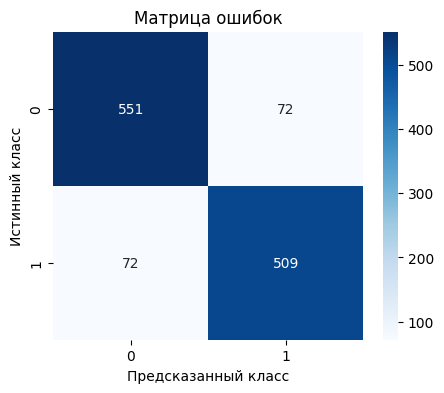


Отчет классификации:
              precision    recall  f1-score   support

           0       0.88      0.88      0.88       623
           1       0.88      0.88      0.88       581

    accuracy                           0.88      1204
   macro avg       0.88      0.88      0.88      1204
weighted avg       0.88      0.88      0.88      1204



In [12]:
# Создаем бинарную целевую переменную на основе медианы обучающей выборки, что предотвращает утечку данных из теста в процесс обучения
median_price = y_train.median()
y_train_class = (y_train > median_price).astype(int)
y_test_class = (y_test > median_price).astype(int)

print("Медиана цены для разделения классов:", round(median_price, 2))
print("Распределение классов в обучении:\n", y_train_class.value_counts(normalize=True).round(2))

# Обучение модели логистической регрессии на всех признаках(max_iter=1000 добавлен для гарантированной сходимости алгоритма)
logreg_model = LogisticRegression(random_state=42, max_iter=1000)
logreg_model.fit(X_train, y_train_class)

# предсказания на тестовой выборке
y_pred_class = logreg_model.predict(X_test)

# Оценка работы модели
accuracy = accuracy_score(y_test_class, y_pred_class)
print("\nТочность (accuracy):", round(accuracy, 4))

# Создание матрицы ошибок
cm = confusion_matrix(y_test_class, y_pred_class)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Матрица ошибок')
plt.ylabel('Истинный класс')
plt.xlabel('Предсказанный класс')
plt.show()

# полный отчет с precision, recall и f1-мерой
print("\nОтчет классификации:")
print(classification_report(y_test_class, y_pred_class))

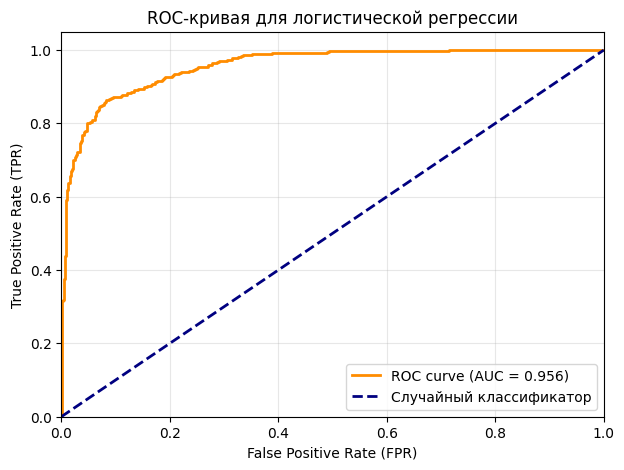

Площадь под ROC-кривой (AUC): 0.956

Интерпретация AUC:
0.9-1.0 — отличное качество
0.8-0.9 — хорошее качество
0.7-0.8 — приемлемое качество
0.6-0.7 — слабое качество
0.5-0.6 — не лучше случайного угадывания


In [14]:
# Получаем вероятности принадлежности к классу 1
y_prob = logreg_model.predict_proba(X_test)[:, 1]

# Вычисляем значения для ROC-кривой
fpr, tpr, thresholds = roc_curve(y_test_class, y_prob)

# Вычисляем площадь под кривой (AUC)
roc_auc = auc(fpr, tpr)

# график
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Случайный классификатор')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC-кривая для логистической регрессии')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

print(f"Площадь под ROC-кривой (AUC): {roc_auc:.3f}")
print("\nИнтерпретация AUC:")
print("0.9-1.0 — отличное качество")
print("0.8-0.9 — хорошее качество")
print("0.7-0.8 — приемлемое качество")
print("0.6-0.7 — слабое качество")
print("0.5-0.6 — не лучше случайного угадывания")